## Import Required Libraries

In [1]:
import time, logging
import os, glob, pickle

import pandas as pd
import seaborn as sns
import numpy as np
import seaborn as sns
import scanpy as sc
import networkx as nx
import gseapy as gp
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import sparse
from matplotlib.colors import LinearSegmentedColormap
from arboreto.utils import load_tf_names
from arboreto.algo import grnboost2

from ctxcore.rnkdb import FeatherRankingDatabase as RankingDatabase
from pyscenic.utils import modules_from_adjacencies
from pyscenic.prune import prune2df
from pyscenic.transform import df2regulons
from pyscenic.aucell import aucell

c:\Users\oonak\anaconda3\envs\pyscenic\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
c:\Users\oonak\anaconda3\envs\pyscenic\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
c:\Users\oonak\anaconda3\envs\pyscenic\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
c:\Users\oonak\anaconda3\envs\pyscenic\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
c:\Users\oonak\anaconda3\envs\pyscenic\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_mtx from `anndata` is dep

### Setting Timestamp

In [2]:
timestamp = time.strftime('%Y%m%d')

## Global Variables

In [3]:
CELL_TYPE = "Activated T cells"
SEED = 42

## Design Definitions

In [4]:
MAIN_COLOR = "#0E2841"
ACCENT_COLOR = "#4E95D9"

NAVY_WHITE = LinearSegmentedColormap.from_list(
    "navy_white",
    ["#0E2841", "#FFFFFF"]
)

COLOR_PALETTE = sns.color_palette(
    [NAVY_WHITE(x) for x in np.linspace(0,1,10)],
    as_cmap=True
)

COLOR_PALETTE_2 = [
    "#0072B2",  # Blue
    "#E69F00",  # Orange
    "#009E73",  # Bluish green
    "#CC79A7",  # Reddish purple
    "#56B4E9",  # Sky blue
    "#D55E00",  # Vermilion
    "#4D4D4D",  # Dark grey
    "#332288",  # Indigo
    "#88CCEE",  # Light cyan
    "#44AA99",  # Teal
    "#117733",  # Dark green
    "#999933",  # Olive
    "#DDCC77",  # Sand
    "#AA4499",  # Purple
    "#882255",  # Wine
]

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#263746",
        "xtick.color": "#465563",
        "ytick.color": "#465563",
        "grid.color": "#D9E1E8",
        "grid.linestyle": "--",
        "grid.linewidth": 0.6,
    }
)

## Data Directory Initialization

In [7]:
DATA_FOLDER="../data"
RESULTS_FOLDER="../x"

SC_EXP_FNAME = os.path.join(DATA_FOLDER, "processed_data/adata_clustered_legacy.h5")
HS_TFS_FNAME = os.path.join(DATA_FOLDER, "pySCENIC/hs_hgnc_tfs.txt")

DATABASES_GLOB = os.path.join(DATA_FOLDER, "pySCENIC/hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather")
MOTIF_ANNOTATIONS_FNAME = os.path.join(DATA_FOLDER, "pySCENIC/motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl")

ADJACENCIES_FNAME = os.path.join(RESULTS_FOLDER, "grn-inference", "adjacencies_t_cell_tumor.tsv")
MODULES_FNAME = os.path.join(RESULTS_FOLDER, "grn-inference", "modules_t_cell_tumor.p")
MOTIFS_FNAME = os.path.join(RESULTS_FOLDER, "grn-inference", "motifs_t_cell_tumor.csv")
REGULONS_FNAME = os.path.join(RESULTS_FOLDER, "grn-inference", "regulons_t_cell_tumor.p")
AUCELL_FNAME = os.path.join(RESULTS_FOLDER, "grn-inference", "aucell_t_cell_tumor.csv")


## Helper Functions

In [8]:
def savefig(path):
    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
    )
    plt.close()

def name(fname):
    return os.path.splitext(os.path.basename(fname))[0]

# Starting Workflow

## 1. Loading Data

In [9]:
adata = sc.read_h5ad(SC_EXP_FNAME)
print(adata)

print(
    f"Initial dimensions: {adata.n_obs:,} cells x "
    f"{adata.n_vars:,} genes"
)

AnnData object with n_obs × n_vars = 13213 × 27792
    obs: 'sample', 'patient', 'region', 'age', 'sex', 'tumor_size', 'lymph_nodes', 'cancer_type', 'grade', 'ER', 'PR', 'HER2', 'Ki67', 'stage', 'treatment', 'tumor_volume', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'size_factors', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.60', 'leiden_res_0.70', 'leiden_res_0.80', 'leiden_res_0.90', 'leiden_res_1.00', 'leiden_res_1.10', 'leiden_res_1.20', 'leiden_r0.20_s0', 'leiden_r0.20_s1', 'leiden_r0.20_s2', 'leiden_r0.20_s3', 'leiden_r0.20_s4', 'leiden_r0.20_s10', 'leiden_r0.20_s21', 'leiden_r0.20_s42', 'leiden_r0.20_s123', 'leiden_r0.20_s2026',

## 2. Extracting Subsets

In [10]:
adata_tumor = adata[
    (adata.obs["region"] == "L")
    & (adata.obs["cell_type"] == CELL_TYPE)
].copy()

print(
    f"Lymph Node - Activated T cells: {adata_tumor.n_obs} cells x "
    f"{adata_tumor.n_vars} genes"
)

Lymph Node - Activated T cells: 45 cells x 27792 genes


### Extracting Raw Counts

In [11]:
X = adata_tumor.X.toarray()

expression_data = pd.DataFrame(
    X,
    columns=adata_tumor.var_names,
    index=adata_tumor.obs_names
)

In [12]:
display(expression_data.head())

gene_symbol,AL627309.1,AL627309.5,AL627309.4,AL669831.2,LINC01409,FAM87B,LINC01128,LINC00115,FAM41C,AL645608.2,...,AL592183.1,AC240274.1,AC004556.3,AC233755.2,AC233755.1,AC136616.1,AC023491.2,AC007325.1,AC007325.4,AC007325.2
barcode,,,,,,,,,,,,,,,,,,,,,
GTGTTAGGTTATGTGC-L2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AGACCATCAATAACCC-L2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
GTGTTAGCACTTCCTG-L2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
GGGCTCATCAGTAGGG-L2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CATTCCGGTGTCCTAA-L2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.050984,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Gene Filtering 

In [13]:
print(f"Min: {expression_data.sum(axis=1).min():.2f}")
print(f"Median: {expression_data.sum(axis=1).median():.2f}")
print(f"Max: {expression_data.sum(axis=1).max():.2f}")

Min: 1464.17
Median: 2075.03
Max: 3086.53


In [14]:
min_cells = max(10, int(np.ceil(0.01 * expression_data.shape[0])))
detected = (expression_data > 0).sum(axis=0)
keep_genes = detected >= min_cells

expression_data_filtered = expression_data.loc[:, keep_genes].copy()

n_before = expression_data.shape[1]
n_after = expression_data_filtered.shape[1]

print("Cell type: Tumor - Activated T cells")
print(f"Cells: {expression_data_filtered.shape[0]:,}")
print(f"Genes before filtering: {n_before:,}")
print(f"Genes after filtering: {n_after:,}")
print(f"Genes removed: {n_before - n_after:,} "
      f"({100 * (n_before - n_after) / n_before:.1f}%)")
print(f"Detection threshold: >= {min_cells} cells")
print(f"DataFrame shape: {expression_data_filtered.shape}")

Cell type: Tumor - Activated T cells
Cells: 45
Genes before filtering: 27,792
Genes after filtering: 1,603
Genes removed: 26,189 (94.2%)
Detection threshold: >= 10 cells
DataFrame shape: (45, 1603)


### Investigating Cell Totals after Filtering

In [15]:
print(f"Min: {expression_data_filtered.sum(axis=1).min():.2f}")
print(f"Median: {expression_data_filtered.sum(axis=1).median():.2f}")
print(f"Max: {expression_data_filtered.sum(axis=1).max():.2f}")

Min: 1018.52
Median: 1394.68
Max: 1728.96


## Derive List of Transcription Factors

In [16]:
tf_names = load_tf_names(HS_TFS_FNAME)
tf_names_present = sorted(set(tf_names).intersection(expression_data_filtered.columns))


In [17]:
print("TFs supplied:", len(tf_names))
print("TFs present:", len(tf_names_present))

TFs supplied: 1839
TFs present: 162


## Input Data Summary

In [18]:
print("Cells:", expression_data_filtered.shape[0])
print("Genes:", expression_data_filtered.shape[1])
print("TFs:", len(tf_names))

Cells: 45
Genes: 1603
TFs: 1839


In [19]:
expression_data_filtered.head()

gene_symbol,ISG15,TNFRSF18,TNFRSF4,SDF4,AURKAIP1,GNB1,RER1,TNFRSF14,RPL22,PARK7,...,MT-CO2,MT-ATP8,MT-ATP6,MT-CO3,MT-ND3,MT-ND4L,MT-ND4,MT-ND5,MT-ND6,MT-CYB
barcode,,,,,,,,,,,,,,,,,,,,,
GTGTTAGGTTATGTGC-L2,0.000000,0.000000,0.0,0.000000,0.0,0.000000,1.095953,1.606246,3.040721,1.606246,...,3.846241,0.000000,4.230173,3.551470,3.802759,0.000000,3.492637,2.829457,0.000000,3.607034
AGACCATCAATAACCC-L2,1.230366,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,2.888000,1.765580,...,3.682853,0.000000,3.900954,3.403520,3.481002,1.765580,2.369302,2.888000,2.112325,3.682853
GTGTTAGCACTTCCTG-L2,1.374119,1.931983,0.0,1.374119,0.0,0.000000,0.000000,1.931983,3.203264,0.000000,...,3.673023,0.000000,3.991364,2.929035,3.075521,2.287957,3.875888,3.075521,0.000000,2.757346
GGGCTCATCAGTAGGG-L2,1.187838,0.000000,0.0,1.187838,0.0,1.715592,0.000000,0.000000,3.169678,0.000000,...,4.206474,0.000000,3.682853,3.841593,3.344972,0.000000,3.169678,2.059232,0.000000,3.978552
CATTCCGGTGTCCTAA-L2,1.552006,1.050984,0.0,0.000000,0.0,1.050984,0.000000,1.050984,2.876058,2.133203,...,3.066429,1.050984,3.426457,3.540622,2.332370,0.000000,3.593162,1.050984,0.000000,3.226290


# PHASE I - GRN Inference (GRNBoost2)

## Run GRNBoost2

In [20]:
%%time

network = grnboost2(
    expression_data=expression_data_filtered, 
    tf_names=tf_names_present, 
    seed=SEED,
    verbose=True
)

preparing dask client
parsing input
creating dask graph
5 partitions
computing dask graph
shutting down client and local cluster
finished
CPU times: total: 14.9 s
Wall time: 29.3 s


**Inferred Network Overview**

In [21]:
display(network.head())

,TF,target,importance
72,UQCRB,ATP6V1F,6.388851
151,SOD1,CCNH,5.981074
119,STUB1,MAGOH,5.756492
72,UQCRB,UBE2A,5.740810
25,NR4A2,YPEL5,5.624843


In [22]:
print("Column Indices: ", network.columns)

print("\nUnique TFs:", network["TF"].nunique())
print("Unique targets:", network["target"].nunique())
print("Unique genes:", len(set(network["TF"]) | set(network["target"])))

print("\nMissing values:\n", network.isna().sum())
print("\nDuplicate edges:", network.duplicated(["TF", "target"]).sum())

Column Indices:  Index(['TF', 'target', 'importance'], dtype='object')

Unique TFs: 162
Unique targets: 1603
Unique genes: 1603

Missing values:
 TF            0
target        0
importance    0
dtype: int64

Duplicate edges: 0


In [23]:
display(pd.DataFrame(network["importance"].describe()))

,importance
count,1.404970e+05
mean,3.156722e-01
std,4.206881e-01
min,3.149689e-17
25%,6.553851e-02
50%,1.935187e-01
75%,3.827132e-01
max,6.388851e+00


### Create Edge Table

In [24]:
edges = network.rename(columns={
    "TF": "source",
    "target": "target",
    "importance": "importance"
}).copy()

edges = edges.dropna()
edges = edges[edges["importance"] >= 0]

# combines repeated TF-Target interactions
edges = (edges.groupby(["source", "target"], as_index=False)["importance"].max())

display(edges)

,source,target,importance
0,ADNP,ABHD17A,8.886766e-07
1,ADNP,AC016831.5,4.081548e-02
2,ADNP,ADGRE5,1.760952e-01
3,ADNP,ADRM1,9.532006e-07
4,ADNP,AHI1,2.168868e-01
...,...,...,...
140492,ZNF831,ZMAT2,8.072841e-01
140493,ZNF831,ZNF331,6.982516e-01
140494,ZNF831,ZNF644,2.125196e-05
140495,ZNF831,ZNHIT3,2.235622e-01


In [26]:
edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "grnboost2_edges_cytoscape.tsv"),
    sep="\t",
    index=False
)

### Edge-Filtering

In [28]:
q95 = edges["importance"].quantile(0.95)
edges_top5pct = edges[edges["importance"] >= q95].copy()

edges_top10_per_tf = (
    edges
    .sort_values("importance", ascending=False)
    .groupby("source", group_keys=False)
    .head(10).copy())

edges_top25_per_tf = (
    edges
    .sort_values("importance", ascending=False)
    .groupby("source", group_keys=False)
    .head(25).copy()
)

In [29]:
print("Full Network:", len(edges))
print("Top 5% globally:", len(edges_top5pct))
print("Top 10 per TF:", len(edges_top10_per_tf))
print("Top 25 per TF:", len(edges_top25_per_tf))

Full Network: 140497
Top 5% globally: 7025
Top 10 per TF: 1620
Top 25 per TF: 4050


## Investigate Adjacency Table Using NetworkX

In [30]:
G = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    edge_attr="importance",
    create_using=nx.DiGraph()
)

In [31]:
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Density:", nx.density(G))

Nodes: 1603
Edges: 140497
Density: 0.05471054195356241


In [32]:
tf_set = set(tf_names_present)

tf_nodes = set(G.nodes()) & tf_set
target_nodes = set(G.nodes())

In [33]:
print("TFs represented in graph:", len(tf_nodes))
print("Genes represented in graph:", len(target_nodes))
print("TFs with outgoing edges:", sum(
    G.out_degree(tf) > 0 for tf in tf_nodes
))

TFs represented in graph: 162
Genes represented in graph: 1603
TFs with outgoing edges: 162


**Standard Topology Metrics**

In [34]:
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

weighted_out_degree = dict(
    G.out_degree(weight="importance")
)

weighted_in_degree = dict(
    G.in_degree(weight="importance")
)

In [35]:
pagerank = nx.pagerank(G, weight="importance")

In [ ]:
H = nx.DiGraph()
H.add_nodes_from(G.nodes())

for u, v, data in G.edges(data=True):
    importance = float(data["importance"])
    H.add_edge(
        u, v,
        distance=1.0 / max(importance, 1e-12)
    )

betweenness = nx.betweenness_centrality(
    H, weight="distance", normalized=True
)

In [36]:
node_metrics = pd.DataFrame({
    "gene": list(G.nodes()),
    "in_degree": [in_degree[n] for n in G.nodes()],
    "out_degree": [out_degree[n] for n in G.nodes()],
    "weighted_in_degree": [
        weighted_in_degree[n] for n in G.nodes()
    ],
    "weighted_out_degree": [
        weighted_out_degree[n] for n in G.nodes()
    ],
    "pagerank": [pagerank[n] for n in G.nodes()],
    # "betweenness": [betweenness[n] for n in G.nodes()]
})

node_metrics["is_TF"] = node_metrics["gene"].isin(tf_set)

tf_ranking = (
    node_metrics[node_metrics["is_TF"]]
    .sort_values("weighted_out_degree", ascending=False)
)

display(tf_ranking.head(10))

,gene,in_degree,out_degree,weighted_in_degree,weighted_out_degree,pagerank,is_TF
336,RPS4X,86,1347,27.0,852.590626,0.000620,True
185,JUNB,77,1370,26.0,684.433464,0.000624,True
119,ELF1,92,1344,28.0,643.018294,0.000634,True
1548,H2AFZ,87,1271,28.0,617.079077,0.000632,True
431,UQCRB,85,1145,25.0,564.841850,0.000616,True
1176,RPL6,81,1249,25.0,545.466189,0.000616,True
628,HNRNPA1,80,1185,26.0,524.543856,0.000622,True
325,RPS10,86,1293,28.0,509.392410,0.000623,True
1553,NR4A2,100,1079,33.0,484.091270,0.000630,True
1379,MAF,107,974,33.0,478.927970,0.000634,True


In [37]:
node_metrics.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "grn_node_metrics.csv"),
    sep="\t",
    index=False
)

**Highly Regulated Genes and TF Convergence**

In [38]:
top_regulated_genes = (
    node_metrics
    .sort_values("in_degree", ascending=False)
    .head(10)
)

display(top_regulated_genes[["gene", "in_degree", "weighted_in_degree"]])

,gene,in_degree,weighted_in_degree
821,SLTM,123,51.0
827,SNHG29,117,35.0
679,MSN,117,39.0
272,PSMB8,117,42.0
861,TLN1,113,42.0
968,CD74,112,36.0
238,OST4,112,36.0
281,RABAC1,111,48.0
1217,SUMO2,111,33.0
1345,GNAI2,111,36.0


In [39]:
top_tfs = tf_ranking.head(10)["gene"].tolist()

tf_target_matrix = (
    edges[edges["source"].isin(top_tfs)]
    .pivot_table(
        index="target",
        columns="source",
        values="importance",
        aggfunc="max",
        fill_value=0
    )
)

tf_target_matrix["n_top_TFs"] = (
    tf_target_matrix[top_tfs] > 0
).sum(axis=1)

convergent_targets = (
    tf_target_matrix
    .sort_values("n_top_TFs", ascending=False)
)

display(convergent_targets.head(10))

source,ELF1,H2AFZ,HNRNPA1,JUNB,MAF,NR4A2,RPL6,RPS10,RPS4X,UQCRB,n_top_TFs
target,,,,,,,,,,,
LINC01943,0.818571,0.779601,0.029727,0.210561,0.279926,0.427949,0.002390,0.530495,0.115564,1.849801,10
GPCPD1,0.129083,0.164407,1.641553,0.196051,0.275135,0.309820,0.556914,0.537098,0.522073,0.624652,10
PDE4B,0.035962,0.011431,0.210879,0.268949,0.193650,0.729167,0.035838,0.043587,0.186217,0.121198,10
BRK1,0.352185,0.178437,0.000016,0.025332,0.121284,0.084576,0.010333,0.255325,3.254347,1.908558,10
TMF1,0.764050,0.538094,0.144168,0.471095,0.230586,0.000029,0.159588,0.155929,0.181915,0.725797,10
PET100,0.000028,0.092449,0.087327,0.676594,3.499698,0.619003,0.944552,0.821529,0.749268,1.914407,10
PFDN5,0.251056,0.254312,0.190960,0.000016,0.167010,0.009518,0.733768,0.074755,2.179792,1.741055,10
GRPEL1,0.082027,0.135923,0.780076,0.456759,0.877379,0.241816,0.088209,0.431262,0.000013,0.125900,10
CTLA4,0.569649,0.198516,0.266243,0.000441,0.264482,0.284799,0.753414,0.099771,0.811905,0.178093,10


**Identify Communities and Regulatory Modules**

In [40]:
G_filtered = nx.from_pandas_edgelist(
    edges_top10_per_tf,
    source="source",
    target="target",
    edge_attr="importance",
    create_using=nx.DiGraph()
)

In [41]:
U = nx.Graph()
U.add_nodes_from(G_filtered.nodes())

for u, v, data in G_filtered.edges(data=True):
    w = float(data["importance"])

    if U.has_edge(u, v):
        U[u][v]["weight"] += w
    else:
        U.add_edge(u, v, weight=w)

communities = nx.community.louvain_communities(
    U,
    weight="weight",
    seed=SEED
)

In [42]:
module_rows = []

for module_id, genes in enumerate(communities, start=1):
    for gene in genes:
        module_rows.append({
            "gene": gene,
            "module": module_id,
            "is_TF": gene in tf_set
        })

modules_df = pd.DataFrame(module_rows)

module_summary = (
    modules_df.groupby("module")
    .agg(
        n_genes=("gene", "nunique"),
        n_TFs=("is_TF", "sum")
    )
    .sort_values("n_genes", ascending=False)
)

display(module_summary.head(10))

,n_genes,n_TFs
module,,
22,71,11
7,59,8
29,57,8
17,55,9
18,52,9
14,51,7
27,49,8
3,48,9
20,47,8


In [43]:
modules_df.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "grn_modules.csv"),
    sep="\t",
    index=False)

## Functional Enrichment of TF Targets

In [44]:
candidate_tfs = tf_ranking.head(20)["gene"].tolist()

background_genes = list(expression_data_filtered.columns)

enrichment_results = []

for tf in candidate_tfs:
    targets = (
        edges.loc[edges["source"] == tf]
        .sort_values("importance", ascending=False)["target"]
        .drop_duplicates()
        .tolist()
    )

    if len(targets) < 10:
        continue

    result = gp.enrichr(
        gene_list=targets,
        gene_sets=[
            "GO_Biological_Process_2023",
            "KEGG_2021_Human",
            "Reactome_2022"
        ],
        organism="hsapiens",  
        outdir=None
    )

    table = result.results.copy()
    table["TF"] = tf
    table["n_targets"] = len(targets)

    enrichment_results.append(table)

In [45]:
if enrichment_results:
    tf_enrichment = pd.concat(
        enrichment_results, ignore_index=True
    )

    tf_enrichment.to_csv(
        os.path.join(RESULTS_FOLDER, "grn-inference", "tf_functional_enrichment.csv"),
        sep="\t",
        index=False
    )

    display(
        tf_enrichment.sort_values("Adjusted P-value")
        [["TF", "Term", "Adjusted P-value", "Genes"]]
        .head(5)
    )

,TF,Term,Adjusted P-value,Genes
3938,RPS4X,GTP Hydrolysis And Joining Of 60S Ribosomal Su...,1.228463e-87,EIF4A2;RPL4;EIF4A1;RPL5;RPL30;RPL3;RPL32;RPL31...
40942,RPS10,GTP Hydrolysis And Joining Of 60S Ribosomal Su...,2.096909e-87,EIF4A2;RPL4;EIF4A1;RPL5;RPL3;RPL32;RPL31;RPL34...
3939,RPS4X,L13a-mediated Translational Silencing Of Cerul...,8.216119e-87,EIF4A2;RPL4;EIF4A1;RPL5;RPL30;RPL3;RPL32;RPL31...
40943,RPS10,L13a-mediated Translational Silencing Of Cerul...,1.448325e-86,EIF4A2;RPL4;EIF4A1;RPL5;RPL3;RPL32;RPL31;RPL34...
30378,RPL6,L13a-mediated Translational Silencing Of Cerul...,9.040526e-86,EIF4A2;RPL4;EIF4A1;RPL5;RPL30;RPL3;RPL32;RPL34...


## Create Table for Cytoscape Import

In [83]:
viz_edges = edges_top10_per_tf.copy()
viz_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "cytoscape_edges.csv"),
    index=False
)

viz_nodes = node_metrics.copy()
viz_nodes = viz_nodes.merge(
    modules_df[["gene", "module"]].drop_duplicates("gene"),
    on="gene",
    how="left"
)
target_genes = set(viz_edges["target"])
viz_nodes["is_target"] = viz_nodes["gene"].isin(target_genes)
viz_nodes["node_type"] = np.select(
    [
        viz_nodes["is_TF"] & viz_nodes["is_target"],
        viz_nodes["is_TF"],
        viz_nodes["is_target"]
    ],
    ["TF_Target", "TF", "Target"],
    default="Other"
)
viz_nodes.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "cytoscape_nodes.csv"),
    index=False
)

## Network Investigation

**Importance Score Distribution**

In [47]:
importance = (
    network["importance"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)
importance = importance[importance > 0]

In [48]:
print("Original skewness:", importance.skew())
print("Log10-transformed skewness:", np.log10(importance).skew())

Original skewness: 3.4127786213934153
Log10-transformed skewness: -2.9071513829586344


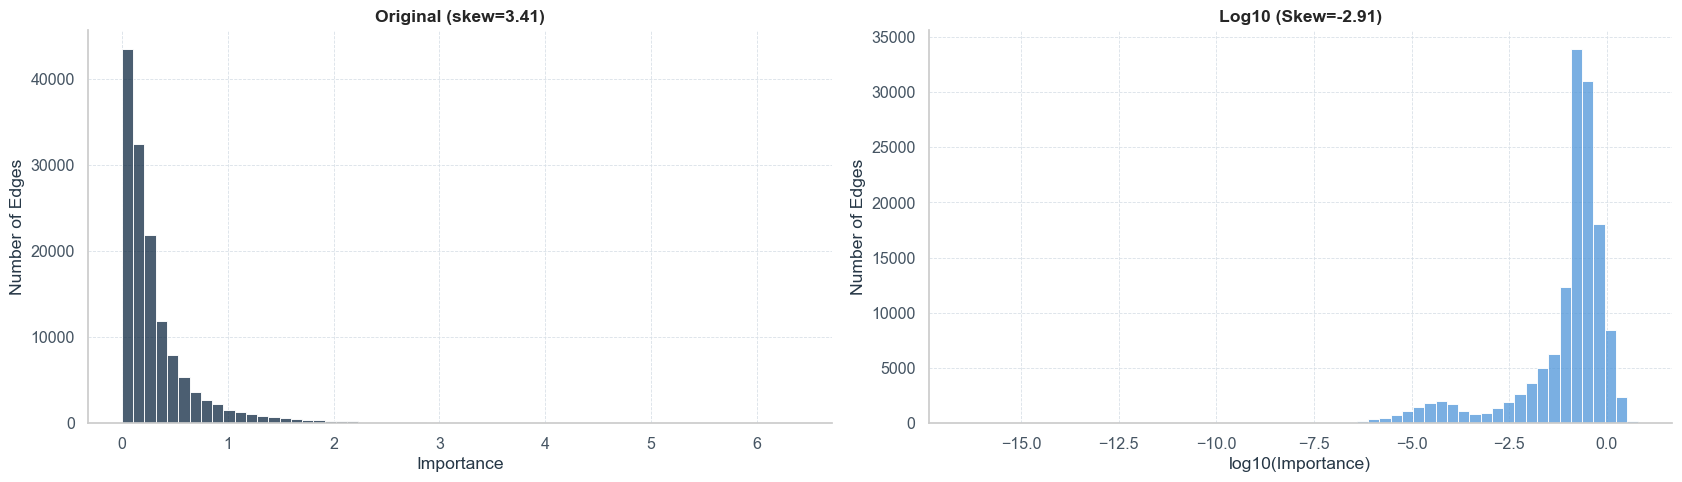

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# Original values
sns.histplot(importance, bins=60, ax=axes[0], color=MAIN_COLOR)
axes[0].set_title(f"Original (skew={importance.skew():.2f})")
axes[0].set_xlabel("Importance")

# Log10-transformed values
log_importance = np.log10(importance)
sns.histplot(log_importance, bins=60, ax=axes[1], color=ACCENT_COLOR)
axes[1].set_title(f"Log10 (Skew={log_importance.skew():.2f})")
axes[1].set_xlabel("log10(Importance)")

for ax in axes:
    ax.set_ylabel("Number of Edges")

plt.tight_layout()
plt.show()

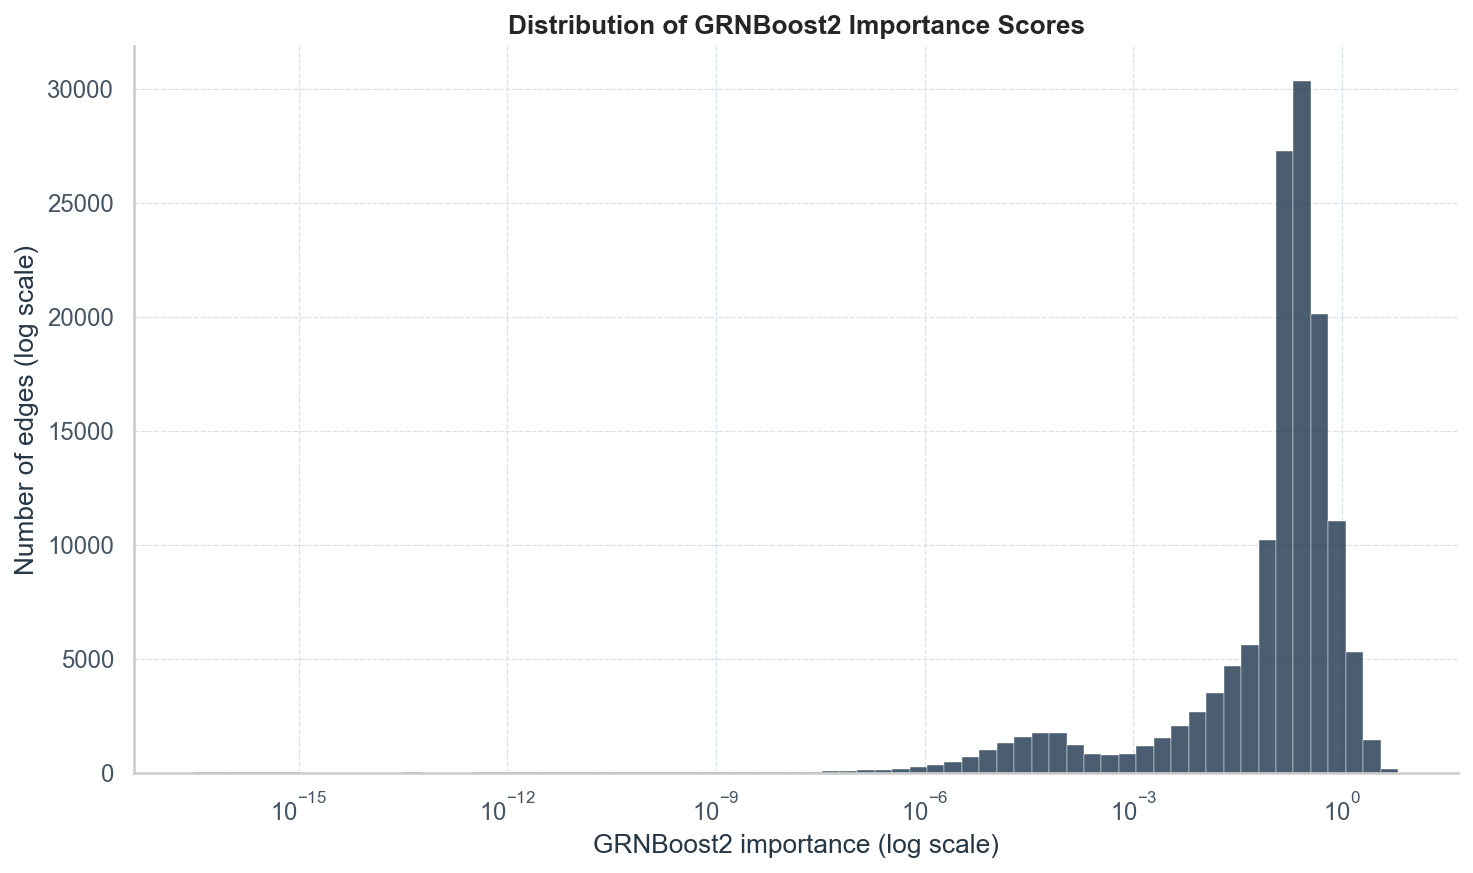

In [52]:
bins = np.logspace(
    np.log10(importance.min()),
    np.log10(importance.max()),
    70
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

sns.histplot(
    importance,
    bins=bins,
    color=MAIN_COLOR,
    linewidth=0.2,
    ax=ax
)

ax.set_xscale("log")
ax.set_xlabel("GRNBoost2 importance (log scale)")
ax.set_ylabel("Number of edges (log scale)")
ax.set_title("Distribution of GRNBoost2 Importance Scores")

plt.tight_layout()
plt.show()

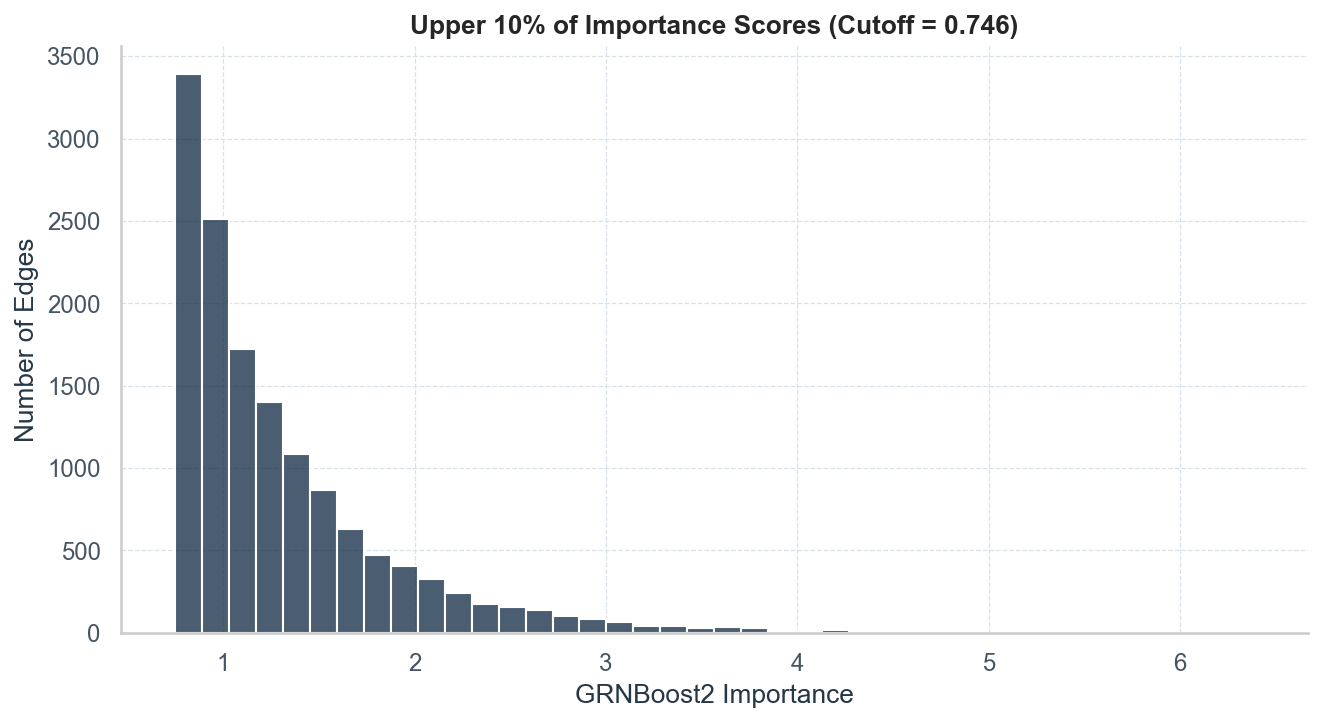

In [53]:
cutoff = importance.quantile(0.90)
upper = importance[importance >= cutoff]

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

sns.histplot(
    upper,
    bins=40,
    color=MAIN_COLOR,
    ax=ax
)

ax.set_xlabel("GRNBoost2 Importance")
ax.set_ylabel("Number of Edges")
ax.set_title(
    f"Upper 10% of Importance Scores (Cutoff = {cutoff:.3f})"
)

plt.tight_layout()
plt.show()

## Investigatint Top-Ranked Edges

In [54]:
top_edges = network.nlargest(
    100, "importance"
).copy()

# Summarize the strongest candidate regulators
top_tf_summary = (
    top_edges.groupby("TF")
    .agg(
        edges_in_top100=("target", "nunique"),
        max_importance=("importance", "max"),
        mean_importance=("importance", "mean")
    )
    .sort_values("max_importance", ascending=False)
)

display(top_tf_summary.head(10))

,edges_in_top100,max_importance,mean_importance
TF,,,
UQCRB,6,6.388851,4.732168
SOD1,2,5.981074,5.082163
STUB1,1,5.756492,5.756492
NR4A2,2,5.624843,5.066797
RBM8A,2,5.591186,5.118714
RPS4X,20,5.558400,4.488831
H2AFZ,4,5.543985,4.853688
KDM5B,1,5.382701,5.382701
ELF1,2,5.242005,4.551496


# PHASE 2 - Prune Modules for Targets (RcisTarget) 

In [55]:
db_fnames = glob.glob(DATABASES_GLOB)
    
dbs = [RankingDatabase(
    fname=fname, name=name(fname)
    ) for fname in db_fnames
]

print(dbs)

[FeatherRankingDatabase(name="hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings")]


In [56]:
modules = list(modules_from_adjacencies(network, expression_data_filtered))

with open(MODULES_FNAME, 'wb') as f:
    pickle.dump(modules, f)


2026-10-13 17:04:51,020 - pyscenic.utils - INFO - Calculating Pearson correlations.

2026-10-13 17:04:51,061 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2026-10-13 17:04:52,289 - pyscenic.utils - INFO - Creating modules.
c:\Users\oonak\anaconda3\envs\pyscenic\lib\site-packages\pyscenic\utils.py:244: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of panda

**Inspect Modules**

In [57]:
print("Total modules:", len(modules))
print("Module type:", type(modules[0]) if modules else None)

if modules:
    print("\nFirst module:")
    print(modules[0])

Total modules: 949
Module type: <class 'ctxcore.genesig.Regulon'>

First module:
[USP8,SNW1,LPIN2,IL18R1,IGFLR1,TAX1BP1,MIDN,TOMM5,CTSC,TPM4,TRAF3IP3,SEMA4D,HNRNPF,PPP2CA,ATP5IF1,CHD3,SUPT5H,CAPN2,TAPBP,HNRNPA3,GPS2,NDUFB10,RSBN1L,COX5A,SPOCK2,ADNP,SPCS2,TBC1D15,ZMAT2,COX7A2,SNHG32,PRKCH,RNF213,NOP10,ARL6IP5,ERLEC1,MIER1,TCF25,USP16,CD58,NDUFA6,TMBIM4,HNRNPH3,SRP19,EVI2A,SIVA1,CHMP5,ATP5MF,MED4,TAGAP,CBX3,MBD2,HNRNPR,CD28,DNTTIP2,ZC3H7A,WDR33,CUL3,NIBAN1,IKZF2,ELK3,RAPGEF6,SDF4,ANTKMT,OSBPL8,ASCC3,ELOVL5,GPRIN3,SNRNP200,SSBP1,PVT1,RALY,ZFP91,HLA-DRA,PPDPF]


**Module TFs and Size Summary**

In [58]:
module_summary = pd.DataFrame([
    {
        "TF": module.transcription_factor,
        "Module": module.name,
        "Number_of_genes": len(module.genes),
    }
    for module in modules
])

print("Total modules:", len(module_summary))
print("Unique TFs:", module_summary["TF"].nunique())

display(
    pd.DataFrame(
        module_summary["Number_of_genes"].describe(
            percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
        )
    )
)

display(
    module_summary.sort_values(
        "Number_of_genes",
        ascending=False
    ).head(20)
)

Total modules: 949
Unique TFs: 162


,Number_of_genes
count,949.000000
mean,141.427819
std,145.617948
min,20.000000
25%,51.000000
50%,78.000000
75%,155.000000
90%,398.600000
95%,483.000000
max,743.000000


,TF,Module,Number_of_genes
903,RPS10,RPS10,743
904,RPS4X,RPS4X,722
871,NAP1L1,NAP1L1,715
910,SMAP2,SMAP2,673
891,RAN,RAN,644
897,REL,REL,612
902,RPL6,RPL6,611
914,SOD1,SOD1,601
843,HNRNPA1,HNRNPA1,601
901,RPL35,RPL35,593


**Distribution of Module Sizes**

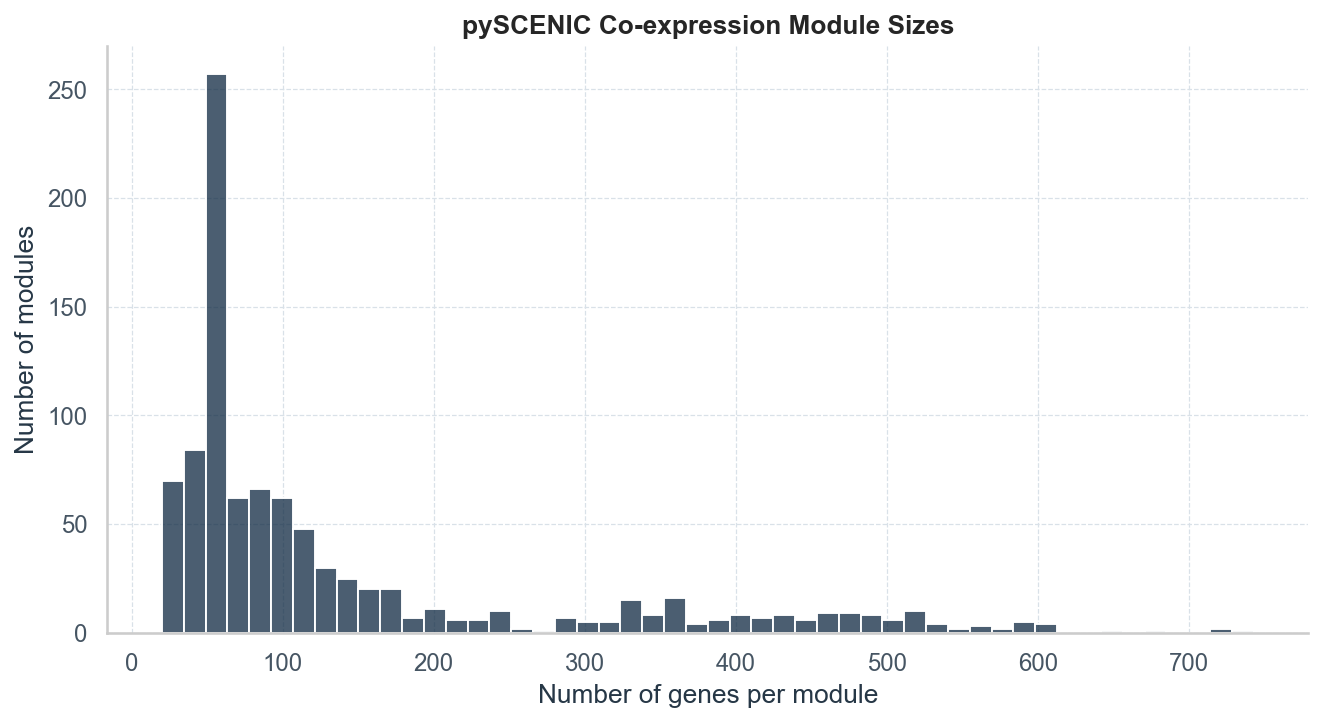

In [59]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

sns.histplot(
    data=module_summary,
    x="Number_of_genes",
    bins=50,
    color=MAIN_COLOR,
    ax=ax
)

ax.set_xlabel("Number of genes per module")
ax.set_ylabel("Number of modules")
ax.set_title("pySCENIC Co-expression Module Sizes")

plt.tight_layout()
plt.show()

**TFs Generating the Broades Modules**

In [60]:
modules_per_tf = (
    module_summary.groupby("TF")
    .agg(
        n_modules=("Module", "count"),
        max_module_size=("Number_of_genes", "max"),
        median_module_size=("Number_of_genes", "median")
    )
    .sort_values("max_module_size", ascending=False)
)

display(modules_per_tf.head(10))

,n_modules,max_module_size,median_module_size
TF,,,
RPS10,6,743,196.5
RPS4X,6,722,292.0
NAP1L1,6,715,159.0
SMAP2,6,673,140.0
RAN,6,644,139.0
REL,6,612,134.5
RPL6,6,611,192.0
HNRNPA1,6,601,155.5
SOD1,6,601,136.0


In [ ]:
#with open(MODULES_FNAME, 'rb') as f:
    #modules = pickle.load(f)

## Motif Pruning

In [61]:
%%time

df = prune2df(dbs, modules, MOTIF_ANNOTATIONS_FNAME)
df.to_csv(MOTIFS_FNAME)

display(df.head())

Enrichment  \
                                                                 AUC   
TF     MotifID                                                         
ATF4   metacluster_111.3                                    0.059395   
BACH1  tfdimers__MD00569                                    0.095147   
BCL11B metacluster_155.23                                   0.110117   
BCLAF1 taipale_tf_pairs__E2F1_ELK1_SGCGCNNNNNNNNNNNCGG...   0.094317   
CHD1   swissregulon__hs__CHD1                               0.103244   

                                                                     \
                                                                NES   
TF     MotifID                                                        
ATF4   metacluster_111.3                                   3.088012   
BACH1  tfdimers__MD00569                                   3.102032   
BCL11B metacluster_155.23                                  4.205167   
BCLAF1 taipale_tf_pairs__E2F1_ELK1_SGCGCNNNNNNNNNNNCGG...  3.004324   
CHD1   swissregulon__hs__CHD1                              3.017078   

                                                                                 \
                                                          MotifSimilarityQvalue   
TF     MotifID                                                                    
ATF4   metacluster_111.3                                           6.250900e-10   
BACH1  tfdimers__MD00569                                           6.256300e-06   
BCL11B metacluster_155.23                                          0.000000e+00   
BCLAF1 taipale_tf_pairs__E2F1_ELK1_SGCGCNNNNNNNNNNNCGG...          4.110780e-06   
CHD1   swissregulon__hs__CHD1                                      0.000000e+00   

                                                                               \
                                                          OrthologousIdentity   
TF     MotifID                                                                  
ATF4   metacluster_111.3                                                  1.0   
BACH1  tfdimers__MD00569                                                  1.0   
BCL11B metacluster_155.23                                                 1.0   
BCLAF1 taipale_tf_pairs__E2F1_ELK1_SGCGCNNNNNNNNNNNCGG...                 1.0   
CHD1   swissregulon__hs__CHD1                                             1.0   

                                                                                                              \
                                                                                                  Annotation   
TF     MotifID                                                                                                 
ATF4   metacluster_111.3                                   motif similar to transfac_pro__M00981 ('V$CREB...   
BACH1  tfdimers__MD00569                                   motif similar to tfdimers__MD00162 ('M01721_fo...   
BCL11B metacluster_155.23                                                         gene is directly annotated   
BCLAF1 taipale_tf_pairs__E2F1_ELK1_SGCGCNNNNNNNNNNNCGG...  motif similar to transfac_pro__M04704 ('V$BCLA...   
CHD1   swissregulon__hs__CHD1                                                     gene is directly annotated   

                                                                                                              \
                                                                                                     Context   
TF     MotifID                                                                                                 
ATF4   metacluster_111.3                                   (weight>75.0%, activating, hg38_10kbp_up_10kbp...   
BACH1  tfdimers__MD00569                                   (weight>75.0%, activating, hg38_10kbp_up_10kbp...   
BCL11B metacluster_155.23                                  (weight>75.0%, activating, hg38_10kbp_up_10kbp...   
BCLAF1 taipale_tf_pairs__E2F1

CPU times: total: 5.7 s
Wall time: 2min 35s



|Column |Meaning|
| --- | --- |
|AUC|Area under the Motif-Recovery Curve|
|NES|Normalized Enrichment Score|
|MotifSimilarityQvalue| Significance of Motif Similarity to an Annotated Motif|
|OrthologousIdentity| Identity Measure associated with Orthologous Motif Annotation|
|Annotation|Annotation Linking the Motif to a TF or Related Motif|
|Context|Regulatory Context Used in Enrichment|
|TargetGenes|Targets Retained for That Enriched Motif/Module|
|RankAtMax|Ranking Position at the mMximum of the Recovery Curve|


In [62]:
regulons = df2regulons(df)

with open(REGULONS_FNAME, 'wb') as f:
    pickle.dump(regulons, f)

Create regulons from a dataframe of enriched features.
Additional columns saved: []


**Summary of all Regulons**

In [63]:
summary = []

for reg in regulons:
    targets = reg.gene2weight

    summary.append({
        "TF": reg.transcription_factor,
        "Regulon": reg.name,
        "N_targets": len(targets),
        "Regulon_score": reg.score,
        "NES": reg.nes,
        "Annotation": reg.annotation,
        "Context": "; ".join(sorted(map(str, reg.context))),
        "Mean_target_weight": (
            sum(targets.values()) / len(targets)
            if targets else None
        )
    })

summary = pd.DataFrame(summary)

summary = summary.sort_values(
    ["N_targets", "Regulon_score"],
    ascending=[False, False]
)

summary.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "regulon_summary.csv"), 
    index=False
)

display(summary.head(10))
print("Total regulons:", len(summary))

,TF,Regulon,N_targets,Regulon_score,NES,Annotation,Context,Mean_target_weight
11,ETS1,ETS1(+),232,4.232091,0.0,,activating; metacluster_34.4.png,0.489472
9,ELF1,ELF1(+),183,4.586759,0.0,,activating; hdpi__FLI1.png,0.658712
21,KLF2,KLF2(+),112,3.354211,0.0,,activating; metacluster_3.3.png,0.495771
20,KLF13,KLF13(+),109,4.098404,0.0,,activating; metacluster_3.11.png,0.424743
22,KLF3,KLF3(+),107,3.260474,0.0,,activating; metacluster_3.4.png,0.357354
6,CHD1,CHD1(+),94,3.106229,0.0,,activating; swissregulon__hs__CHD1.png,0.684365
3,BCL11B,BCL11B(+),86,4.205167,0.0,,activating; metacluster_155.23.png,0.654137
23,KLF6,KLF6(+),82,2.112800,0.0,,activating; metacluster_131.7.png,0.370669
0,ATF4,ATF4(+),76,4.234201,0.0,,activating; metacluster_111.3.png,0.475421
30,SP3,SP3(+),75,3.077692,0.0,,activating; transfac_pro__M01219.png,0.507054


Total regulons: 38


### Export Regulons to Cytoscape Edge Table

In [64]:
edges = []

for reg in regulons:
    tf = reg.transcription_factor

    for target, weight in reg.gene2weight.items():
        edges.append({
            "source": tf,
            "target": target,
            "weight": weight,
            "regulon": reg.name,
            "regulon_score": reg.score,
            "context": "; ".join(sorted(map(str, reg.context)))
        })

edges = pd.DataFrame(edges)

edges = (
    edges.sort_values("weight", ascending=False)
         .drop_duplicates(["source", "target"])
)

edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "activated_Tcell_regulon_edges.csv"),
    index=False
)

print("TF-target edges:", len(edges))
print("Unique TFs:", edges["source"].nunique())
print("Unique target genes:", edges["target"].nunique())

TF-target edges: 2011
Unique TFs: 38
Unique target genes: 761


## Create Small Subnetwork for individual TFs

**Regulon Creation Summary**

In [65]:
print("Enrichment dataframe shape:", df.shape)
print("Unique TFs:", df.index.get_level_values("TF").nunique())
print("Unique motifs:", df.index.get_level_values("MotifID").nunique())

print("Number of regulons:", len(regulons))

regulons_df = pd.DataFrame([
    {
        "Regulon": regulon.name,
        "TF": regulon.transcription_factor,
        "N_Targets": len(regulon.genes),
    }
    for regulon in regulons[:10]
])

display(regulons_df)

Enrichment dataframe shape: (287, 8)
Unique TFs: 38
Unique motifs: 138
Number of regulons: 38


,Regulon,TF,N_Targets
0,ATF4(+),ATF4,76
1,BACH1(+),BACH1,45
2,BATF(+),BATF,12
3,BCL11B(+),BCL11B,86
4,BCLAF1(+),BCLAF1,50
5,CEBPB(+),CEBPB,11
6,CHD1(+),CHD1,94
7,CHURC1(+),CHURC1,34
8,CREM(+),CREM,18
9,ELF1(+),ELF1,183


**Investigate Retained Target Genes**

In [66]:
enrichment_summary = df.reset_index()

display(
    enrichment_summary[
        [
            ("TF", ""),
            ("MotifID", ""),
            ("Enrichment", "NES"),
            ("Enrichment", "AUC"),
            ("Enrichment", "TargetGenes"),
        ]
    ].head(5)
)

enrichment_summary["n_targets"] = (
    enrichment_summary[("Enrichment", "TargetGenes")].apply(len)
)

display(
    enrichment_summary[
        [
            ("TF", ""),
            ("MotifID", ""),
            ("Enrichment", "NES"),
            ("Enrichment", "AUC"),
            ("Enrichment", "TargetGenes"),
        ]
    ].sort_values(("Enrichment", "NES"), ascending=False).head(5)
)

TF                                            MotifID Enrichment  \
                                                                    NES   
0    ATF4                                  metacluster_111.3   3.088012   
1   BACH1                                  tfdimers__MD00569   3.102032   
2  BCL11B                                 metacluster_155.23   4.205167   
3  BCLAF1  taipale_tf_pairs__E2F1_ELK1_SGCGCNNNNNNNNNNNCG...   3.004324   
4    CHD1                             swissregulon__hs__CHD1   3.017078   

                                                                
        AUC                                        TargetGenes  
0  0.059395  [(DGKA, 1.5804127574737201), (GNL3, 0.47882107...  
1  0.095147  [(RORA, 0.6334451123519842), (FRYL, 0.62769540...  
2  0.110117  [(FKBP5, 0.4664819362565343), (KMT2E, 0.468645...  
3  0.094317  [(NCK2, 0.48990574659364783), (RORA, 0.4883140...  
4  0.103244  [(ZMYM2, 3.5155349697589524), (CNOT6L, 1.20094...

TF                                            MotifID Enrichment  \
                                                                     NES   
184  STAT1                                  tfdimers__MD00007   7.970107   
187  STAT1                                    metacluster_2.6   6.450593   
86   STAT1                                  tfdimers__MD00007   5.987614   
185  STAT1                                    metacluster_2.9   5.793880   
162   ELK3  taipale_tf_pairs__ETV2_DLX3_RSCGGAANNNNNNNTAAT...   5.776548   

                                                                  
          AUC                                        TargetGenes  
184  0.195255  [(GNG5, 1.9719849876523798), (SH3KBP1, 1.02402...  
187  0.162412  [(EHD4, 1.244005827493907), (LY6E, 1.445928459...  
86   0.142018  [(TLN1, 1.233116178967026), (MPC2, 1.048158407...  
185  0.148218  [(CD3D, 1.3430673622218754), (CD82, 2.35164557...  
162  0.159928  [(ADNP, 0.8800033696024816), (MRPS36, 0.960331...

In [ ]:
#with open(REGULONS_FNAME, 'rb') as f:
    #regulons = pickle.load(f)

# PHASE 3 - Cellular Regulon Enrichment Matrix (AUCell)

In [67]:
%%time

auc_mtx = aucell(expression_data_filtered, regulons, num_workers=4)


CPU times: total: 46.9 ms
Wall time: 10.1 s


In [68]:
auc_mtx.to_csv(AUCELL_FNAME)

In [69]:
print("AUCell matrix shape:", auc_mtx.shape)
display(auc_mtx.head())

AUCell matrix shape: (45, 38)


Regulon,ATF4(+),BACH1(+),BATF(+),BCL11B(+),BCLAF1(+),CEBPB(+),CHD1(+),CHURC1(+),CREM(+),ELF1(+),...,REL(+),RUNX3(+),SP3(+),STAT1(+),TRIM28(+),YY1(+),ZBTB1(+),ZFX(+),ZNF281(+),ZNF524(+)
Cell,,,,,,,,,,,,,,,,,,,,,
GTGTTAGGTTATGTGC-L2,0.000000,0.000000,0.000000,0.008846,0.0,0.0,0.000000,0.0,0.001691,0.003890,...,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
AGACCATCAATAACCC-L2,0.001931,0.000000,0.017933,0.000000,0.0,0.0,0.000086,0.0,0.027402,0.019065,...,0.0,0.001885,0.002319,0.008704,0.000000,0.0,0.0,0.0,0.0,0.0
GTGTTAGCACTTCCTG-L2,0.000000,0.003483,0.000000,0.010452,0.0,0.0,0.000000,0.0,0.010905,0.023157,...,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
GGGCTCATCAGTAGGG-L2,0.000000,0.000000,0.000000,0.011373,0.0,0.0,0.000000,0.0,0.000000,0.007907,...,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
CATTCCGGTGTCCTAA-L2,0.000000,0.000000,0.000000,0.006319,0.0,0.0,0.001297,0.0,0.000000,0.006200,...,0.0,0.000000,0.000000,0.000000,0.000006,0.0,0.0,0.0,0.0,0.0


In [70]:
auc_summary = pd.DataFrame({
    "mean_AUC": auc_mtx.mean(axis=0),
    "median_AUC": auc_mtx.median(axis=0),
    "sd_AUC": auc_mtx.std(axis=0),
    "variance_AUC": auc_mtx.var(axis=0)
})

auc_summary.index = (
    auc_summary.index
    .astype(str)
    .str.replace(r"\(\+\)$", "", regex=True)
)

auc_summary = auc_summary.sort_values(
    "variance_AUC", ascending=False
)

auc_summary.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "aucell_variability_summary.csv")
)

display(auc_summary.head(10))

,mean_AUC,median_AUC,sd_AUC,variance_AUC
Regulon,,,,
STAT1,0.009220,0.002701,0.018436,0.000340
CREM,0.012865,0.010707,0.014169,0.000201
KLF6,0.021452,0.023727,0.011145,0.000124
MXD4,0.006309,0.003946,0.009680,0.000094
JUN,0.002331,0.000000,0.009239,0.000085
NR3C1,0.011193,0.010601,0.009158,0.000084
ELF1,0.014344,0.013190,0.009157,0.000084
ELK3,0.001253,0.000000,0.007822,0.000061
CHD1,0.002343,0.000000,0.007051,0.000050


# Cytoscape 

In [84]:
selected_tfs = ["HIF1A", "EPAS1", "NFE2L2", "ATF4", "XBP1"]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_hypoxia_stress.csv"),
    index=False
)

In [85]:
selected_tfs = [
    "TWIST1", "SNAI1", "SNAI2", "ZEB1", "ZEB2",
    "FOXC2", "GRHL2", "OVOL1", "OVOL2"
]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_EMT_plasticity.csv"),
    index=False
)

In [86]:
selected_tfs = [
    "JUN", "JUNB", "JUND", "FOS", "FOSB",
    "FOSL1", "FOSL2", "RELA", "NFKB1", "STAT3"
]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_AP1_inflammation.csv"),
    index=False
)

In [87]:
selected_tfs = [
    "FOXC2", "TEAD1", "TEAD4", "YAP1", "WWTR1",
    "SMAD2", "SMAD3", "SMAD4", "RUNX1"
]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_migration_invasion.csv"),
    index=False
)

In [88]:
selected_tfs = [
    "E2F1", "E2F2", "E2F3", "MYC", "MYCN",
    "FOXM1", "TP53", "RB1"
]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_proliferation_outgrowth.csv"),
    index=False
)

In [89]:
selected_tfs = [
    "SOX4", "SOX9", "ID1", "ID2", "ID3",
    "KLF4", "STAT3", "MYC"
]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_stemness_plasticity.csv"),
    index=False
)

In [90]:
selected_tfs = [
    "NR2F1", "TP53", "FOXO3", "ATF4", "SMAD2", "SMAD3"
]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_dormancy_relapse.csv"),
    index=False
)


In [91]:
selected_tfs = [
    "ESR1", "PGR", "GATA3", "FOXA1", "FOXC1", "KLF5"
]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_breast_lineage.csv"),
    index=False
)

In [92]:
selected_tfs = ["NFE2L2", "JUNB", "FOSB", "ATF4", "XBP1"]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_oxidative_stress.csv"),
    index=False
)

In [93]:
selected_tfs = ["STAT1", "STAT3", "STAT4", "STAT5", "STAT6"]

focused_edges = edges[
    edges["source"].isin(selected_tfs)
].copy()

focused_edges.to_csv(
    os.path.join(RESULTS_FOLDER, "grn-inference", "subnetworks", "selected_TF_subnetwork_cytokine_binding.csv"),
    index=False
)

# Data Summary

| Output Files | Description |
|--|--|
|adjacencies.tsv| Candidate TF-Target relationships and importance scores |
|regulons.csv| TFs and their inferred target genes |
|motifs.csv| Motif enrichment and evidence supporting TF-target links |
|auc_mtx.csv| Regulon activity across cells |